In [ ]:
# Cau hinh chung
import os, re, json, glob, pickle, random, math, unicodedata, gc
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer, tokenizer_from_json
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Input, Embedding, Conv1D, MaxPooling1D, Bidirectional, LSTM, Dense, Dropout, Concatenate
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score, average_precision_score, roc_curve
from xgboost import XGBClassifier
from urllib.parse import urlparse

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
FILE_LABEL_PHISHING = 0    # 0 = phishing, 1 = legit
MAX_LEN = 200              # do dai mã URL
EPOCHS = 15                # so epoch train
BATCH = 512
MAX_ROWS = None            # None la dung; 
MAX_AUG = 40000            # max dong augmentation homoglyph 
MAX_AUG_BRAND = 30000      # toi da so dong augmentation gia mao thuong hieu
F2_MAX_FEATURES = 10000    # TF-IDF F2: limit so tu 
F2_MIN_DF = 5              # TF-IDF F2: token phai xuat hien o min 5 URL train
F2_SVD_DIM = 128           # F2: so chieu sau khi giam chieu bang SVD
print("GPU:", tf.config.list_physical_devices("GPU"))  # check GPU 


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [ ]:
# Tim file du lieu
candidates = sorted(glob.glob("/kaggle/input/datasets/cuongvnc/dataset-url-v6/dataset_url_06.csv", recursive=True))
DATA_PATH = next((p for p in candidates if os.path.exists(p)), None)
assert DATA_PATH, "Khong tim thay dataset_url_06.csv hay dataset_url_05.csv, hay upload file len Kaggle dataset"
print("Dung file:", DATA_PATH)
# CHI doc 2 cot can dung (url, label), url ep kieu str: tranh DtypeWarning
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig", usecols=["url", "label"], dtype={"url": str})  
print("So dong:", len(df), "| cot:", list(df.columns))
print(df["label"].value_counts().to_dict())  # phan bo nhan goc trong file


Dung file: /kaggle/input/datasets/cuongvnc/dataset-url-v6/dataset_url_06.csv
So dong: 2978799 | cot: ['url', 'label']
{0: 1619288, 1: 1359511}


In [ ]:
# checktrong file co dung quy uoc 0 = phishing, 1 = legit khong
def registrable_domain(url):
    # lay domain ủl dang ky: host bo subdomain, giu 2 phan cuoi hoac 3 phan neu hau to 2 tang
    try:
        host = urlparse(url).netloc.lower().split(":")[0].split("@")[-1]
    except Exception:
        return ""
    if re.fullmatch(r"\d+\.\d+\.\d+\.\d+", host):  # IP thi giu nguyen host donail
        return host
    parts = host.split(".")
    two_level = {"co.uk", "com.au", "com.vn", "net.vn", "org.vn", "edu.vn", "gov.vn", "co.jp", "com.br"}
    if len(parts) >= 3 and ".".join(parts[-2:]) in two_level:
        return ".".join(parts[-3:])
    return ".".join(parts[-2:]) if len(parts) >= 2 else host

FAMOUS = {"youtube.com", "wikipedia.org", "amazon.com", "facebook.com"}
df["_rd"] = df["url"].astype(str).apply(registrable_domain)
g = df[df["_rd"] == "google.com"]
print("google.com -> tong:", len(g), "| phishing:", int((g["label"] == FILE_LABEL_PHISHING).sum()), "(chu yeu docs/sites/drive, khong tinh vao kiem tra)")
fam = df[df["_rd"].isin(FAMOUS)]
ip_mask = df["url"].astype(str).str.contains(r"\d+\.\d+\.\d+\.\d+", regex=True)
ip_rows = df[ip_mask]
print("Domain noi tieng -> ti le nhan legit (phai ~1.0):",
      (fam["label"] == 1).mean() if len(fam) else "khong co mau")
print("URL chua IP -> ti le nhan phishing (phai ~1.0):",
      (ip_rows["label"] == FILE_LABEL_PHISHING).mean() if len(ip_rows) else "khong co mau")
assert (fam["label"] == 1).mean() > 0.9, "Nhan domain noi tieng lech quy uoc, dung train voi!"
assert (ip_rows["label"] == FILE_LABEL_PHISHING).mean() > 0.9, "Nhan URL IP lech quy uoc, dung train voi!"
df = df.drop(columns=["_rd"])
print("Sanity check PASSED: 0 = phishing, 1 = legit")


google.com -> tong: 8489 | phishing: 8105 (chu yeu docs/sites/drive, khong tinh vao kiem tra)
Domain noi tieng -> ti le nhan legit (phai ~1.0): 0.9983052642728525
URL chua IP -> ti le nhan phishing (phai ~1.0): 0.9981220297409168
Sanity check PASSED: 0 = phishing, 1 = legit


In [ ]:
# Lam sach + chuyen ve nhan 0 1 de train
df["url"] = df["url"].astype(str).str.strip().str.lower()
df = df[~df["url"].str.contains(" ", regex=False)]  # bo URL chua khoang trang
df = df[~df["url"].str.endswith("...")]              # bo URL bi cat cut
df = df.drop_duplicates(subset=["url"])              # dedup
if MAX_ROWS:  # lay mau nhanh de thu chay
    df = df.sample(n=min(MAX_ROWS, len(df)), random_state=SEED)
df["y"] = (df["label"] == FILE_LABEL_PHISHING).astype(int)  # nhan noi bo: 1 = phishing
print("Sau lam sach:", len(df), "| phishing:", int(df["y"].sum()), "| legit:", int((1 - df["y"]).sum()))


Sau lam sach: 2911610 | phishing: 1552128 | legit: 1359482


In [ ]:
# Chia train/val/test theo nhom domain
df["_rd"] = df["url"].apply(registrable_domain)
gss = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=SEED)
tr_idx, te_idx = next(gss.split(df, groups=df["_rd"]))
train_df, test_df = df.iloc[tr_idx], df.iloc[te_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=SEED)
tr2_idx, va_idx = next(gss2.split(train_df, groups=train_df["_rd"]))
train_df, val_df = train_df.iloc[tr2_idx], train_df.iloc[va_idx]
print("train/val/test:", len(train_df), len(val_df), len(test_df))
print("Ti le phishing train/val/test:",
      round(train_df["y"].mean(), 4), round(val_df["y"].mean(), 4), round(test_df["y"].mean(), 4))


train/val/test: 2414670 226603 270337
Ti le phishing train/val/test: 0.5396 0.4854 0.5153


In [ ]:
# Can bang lop CHi tren tap train - downsample lop dong ve bang lop it
n_min = int(min(train_df["y"].sum(), (1 - train_df["y"]).sum()))
train_bal = pd.concat([
    train_df[train_df["y"] == 1].sample(n=n_min, random_state=SEED),
    train_df[train_df["y"] == 0].sample(n=n_min, random_state=SEED),
]).sample(frac=1, random_state=SEED)
print("Train sau can bang:", len(train_bal), "| phishing:", int(train_bal["y"].sum()))


Train sau can bang: 2223664 | phishing: 1111832


In [ ]:
# Dinh nghia dac trung 08: 18 cu + Nhom 2 (brand/tu khoa) + Nhom 3 (do ngau nhien) + 9 homoglyph = 41
# QUY TAC QUAN TRONG: 9 dac trung homoglyph tinh tu URL GOC; 32 dac trung con lai +
# input tokenizer tinh tu URL DA SKELETONIZE (giai ma punycode + map confusable ve Latin).
# Whitelist luon so khop tren domain GOC, khong bao gio so tren skeleton.
BRANDS = ["google", "facebook", "amazon", "apple", "microsoft", "netflix", "paypal",
          "binance", "metamask", "github", "linkedin", "twitter", "instagram", "telegram",
          "vietcombank", "techcombank", "vietinbank", "bidv", "agribank", "sacombank",
          "acb", "mb", "vpbank", "momo", "zalopay", "viettel", "vinaphone", "mobifone",
          "shopee", "lazada", "tiki", "vneid", "dichvucong"]
SUS_KW = ["login", "verify", "signin", "secure", "account", "update", "confirm", "free", "bonus",
          "nhan-thuong", "trung-thuong", "mien-phi", "khuyen-mai", "tang-qua", "nhan-qua",
          "rut-tien", "nap-tien", "nhanqua", "trungthuong", "uu-dai", "nhan-tien"]
SUS_TLD = {".top", ".xyz", ".club", ".online", ".site", ".fun", ".icu", ".buzz", ".live",
           ".vip", ".cc", ".ru", ".tk", ".ml", ".ga"}

# Ban do ky tu confusable -> Latin (theo UTS #39; 41 ky tu, CHI map chu cai, khong map so).
CONFUSABLE_MAP = {
    "\u0251": "a",
    "\u03b1": "a",
    "\u0430": "a",
    "\u2c81": "a",
    "\uab64": "a",
    "\U0001d6c2": "a",
    "\U0001d6fc": "a",
    "\U0001d736": "a",
    "\U0001d770": "a",
    "\U0001d7aa": "a",
    # b
    "\u0184": "b",
    "\u03b2": "b",
    "\u042c": "b",
    "\u0432": "b",
    "\u07d5": "b",
    "\u13cf": "b",
    "\u1472": "b",
    "\u15af": "b",
    "\U0001031c": "b",
    # c
    "\u03f2": "c",
    "\u0441": "c",
    "\u1004": "c",
    "\u105a": "c",
    "\u1c83": "c",
    "\u1d04": "c",
    "\u2ca5": "c",
    "\uabaf": "c",
    "\U0001043d": "c",
    #d
    "\u0434": "d",
    "\u0501": "d",
    "\u13e7": "d",
    "\u146f": "d",
    "\ua4d2": "d",
    # e
    "\u03b5": "e",
    "\u0435": "e",
    "\u04bd": "e",
    "\uab32": "e",
    # f
    "\u017f": "f",
    "\u0192": "f",
    "\u0284": "f",
    "\u0584": "f",
    "\u1e9d": "f",
    "\ua799": "f",
    "\uab35": "f",
    # g
    "\u018d": "g",
    "\u0261": "g",
    "\u0581": "g",
    "\u1d83": "g",
    # h
    "\u043d": "h",
    "\u04ba": "h",
    "\u04bb": "h",
    "\u0570": "h",
    "\u10b9": "h",
    "\u13c2": "h",
    # i
    "\u0131": "i",
    "\u0269": "i",
    "\u026a": "i",
    "\u03b9": "i",
    "\u0456": "i",
    "\u0582": "i",
    "\u13a5": "i",
    "\u2c93": "i",
    "\ua647": "i",
    "\uab75": "i",
    "\U000118c3": "i",
    "\U0001d6a4": "i",
    "\U0001d6ca": "i",
    "\U0001d704": "i",
    "\U0001d73e": "i",
    "\U0001d778": "i",
    "\U0001d7b2": "i",
    # j
    "\u0237": "j",
    "\u03f3": "j",
    "\u0458": "j",
    "\u0575": "j",
    "\U0001d6a5": "j",
    # k
    "\u03ba": "k",
    "\u043a": "k",
    # l
    "\u0196": "l",
    "\u01c0": "l",
    "\u0399": "l",
    "\u0406": "l",
    "\u04c0": "l",
    "\u04cf": "l",
    "\u05d5": "l",
    "\u05df": "l",
    "\u0627": "l",
    "\u07ca": "l",
    "\u16c1": "l",
    "\u16d0": "l",
    "\u2110": "l",
    "\u2111": "l",
    "\u2c92": "l",
    "\u2d4a": "l",
    "\u2d4f": "l",
    "\ua4f2": "l",
    "\ua56f": "l",
    "\ua781": "l",
    "\ua7ae": "l",
    "\ua7fe": "l",
    "\ufe8d": "l",
    "\ufe8e": "l",
    "\uff29": "l",
    "\U0001028a": "l",
    "\U00010309": "l",
    "\U0001050e": "l",
    "\U00010926": "l",
    "\U00010c3e": "l",
    "\U00010ca5": "l",
    "\U00016f28": "l",
    "\U0001d408": "l",
    "\U0001d43c": "l",
    "\U0001d470": "l",
    "\U0001d4d8": "l",
    "\U0001d540": "l",
    "\U0001d574": "l",
    "\U0001d5a8": "l",
    "\U0001d5dc": "l",
    "\U0001d610": "l",
    "\U0001d644": "l",
    "\U0001d678": "l",
    "\U0001d6b0": "l",
    "\U0001d6ea": "l",
    "\U0001d724": "l",
    "\U0001d75e": "l",
    "\U0001d798": "l",
    "\U0001ee00": "l",
    "\U0001ee80": "l",
    # m
    "\u043c": "m",
    # n
    "\u03b7": "n",
    "\u043f": "n",
    "\u0578": "n",
    "\u057c": "n",
    # o
    "\u03b4": "o",
    "\u03bf": "o",
    "\u03c3": "o",
    "\u03ed": "o",
    "\u043e": "o",
    "\u0585": "o",
    "\u05e1": "o",
    "\u0647": "o",
    "\u06be": "o",
    "\u06c1": "o",
    "\u06d5": "o",
    "\u07cb": "o",
    "\u0840": "o",
    "\u0d20": "o",
    "\u101d": "o",
    "\u10ff": "o",
    "\u110b": "o",
    "\u11bc": "o",
    "\u1a45": "o",
    "\u1c82": "o",
    "\u1d0f": "o",
    "\u1d11": "o",
    "\u2c9f": "o",
    "\u3147": "o",
    "\uab3d": "o",
    "\ufba6": "o",
    "\ufba7": "o",
    "\ufba8": "o",
    "\ufba9": "o",
    "\ufbaa": "o",
    "\ufbab": "o",
    "\ufbac": "o",
    "\ufbad": "o",
    "\ufee9": "o",
    "\ufeea": "o",
    "\ufeeb": "o",
    "\ufeec": "o",
    "\uffb7": "o",
    "\U0001042c": "o",
    "\U000104ea": "o",
    "\U0001092c": "o",
    "\U00010d07": "o",
    "\U00011124": "o",
    "\U000118c8": "o",
    "\U000118d7": "o",
    "\U0001d6d0": "o",
    "\U0001d6d4": "o",
    "\U0001d70a": "o",
    "\U0001d70e": "o",
    "\U0001d744": "o",
    "\U0001d748": "o",
    "\U0001d77e": "o",
    "\U0001d782": "o",
    "\U0001d7b8": "o",
    "\U0001d7bc": "o",
    "\U0001ee24": "o",
    "\U0001ee84": "o",
    # p
    "\u00fe": "p",
    "\u01bf": "p",
    "\u03c1": "p",
    "\u03f1": "p",
    "\u03f8": "p",
    "\u0440": "p",
    "\u2ca3": "p",
    "\u2ccf": "p",
    "\U0001d6d2": "p",
    "\U0001d6e0": "p",
    "\U0001d70c": "p",
    "\U0001d71a": "p",
    "\U0001d746": "p",
    "\U0001d754": "p",
    "\U0001d780": "p",
    "\U0001d78e": "p",
    "\U0001d7ba": "p",
    "\U0001d7c8": "p",
    # q
    "\u051b": "q",
    "\u0563": "q",
    "\u0566": "q",
    # r
    "\u0433": "r",
    "\u1d26": "r",
    "\u2c85": "r",
    "\uab47": "r",
    "\uab48": "r",
    "\uab81": "r",
    "\U00016a19": "r",
    # s
    "\u01bd": "s",
    "\u03c2": "s",
    "\u0455": "s",
    "\u0d1f": "s",
    "\ua731": "s",
    "\uabaa": "s",
    "\U00010448": "s",
    "\U000118c1": "s",
    # t
    "\u03c4": "t",
    "\u0442": "t",
    # u
    "\u028b": "u",
    "\u03bc": "u",
    "\u03c5": "u",
    "\u057d": "u",
    "\u1d1c": "u",
    "\ua79f": "u",
    "\uab4e": "u",
    "\uab52": "u",
    "\U000104f6": "u",
    "\U000118d8": "u",
    "\U0001d6d6": "u",
    "\U0001d710": "u",
    "\U0001d74a": "u",
    "\U0001d784": "u",
    "\U0001d7be": "u",
    # v
    "\u03bd": "v",
    "\u0475": "v",
    "\u05d8": "v",
    "\u1d20": "v",
    "\uaba9": "v",
    "\U00011706": "v",
    "\U000118c0": "v",
    "\U0001d6ce": "v",
    "\U0001d708": "v",
    "\U0001d742": "v",
    "\U0001d77c": "v",
    "\U0001d7b6": "v",
    # w
    "\u026f": "w",
    "\u03c9": "w",
    "\u0448": "w",
    "\u0461": "w",
    "\u051d": "w",
    "\u0561": "w",
    "\u1d21": "w",
    "\u2cbd": "w",
    "\ua7fa": "w",
    "\uab83": "w",
    "\uaba4": "w",
    "\U0001170a": "w",
    "\U0001170e": "w",
    "\U0001170f": "w",
    # x
    "\u03c7": "x",
    "\u0445": "x",
    "\u1541": "x",
    "\u157d": "x",
    "\u1763": "x",
    "\U00010cc2": "x",
    # y
    "\u0263": "y",
    "\u028f": "y",
    "\u03b3": "y",
    "\u0443": "y",
    "\u04af": "y",
    "\u10e7": "y",
    "\u1d8c": "y",
    "\u1eff": "y",
    "\u213d": "y",
    "\u2ca9": "y",
    "\uab5a": "y",
    "\U000118c4": "y",
    "\U000118dc": "y",
    "\U0001d6c4": "y",
    "\U0001d6fe": "y",
    "\U0001d738": "y",
    "\U0001d772": "y",
    "\U0001d7ac": "y",
    # z
    "\u1d22": "z",
    "\u2c6c": "z",
    "\u2c8d": "z",
    "\u2d2d": "z",
    "\uab93": "z",
}
# Map Latin sang confusable dung cho augmentation: moi chu Latin co 1-2 ban confusable
REV_MAP = {"a": ["\u0430", "\u03b1"], "e": ["\u0435", "\u03b5"],
           "o": ["\u043e", "\u03bf"], "p": ["\u0440", "\u03c1"],
           "c": ["\u0441"], "x": ["\u0445", "\u03c7"], "y": ["\u0443", "\u03b3"],
           "i": ["\u0456", "\u03b9"], "j": ["\u0458"],
           "s": ["\u0455", "\u03c2"], "h": ["\u04bb", "\u043d"],
           "d": ["\u0501", "\u0434"], "k": ["\u043a", "\u03ba"],
           "m": ["\u043c"], "t": ["\u0442", "\u03c4"],
           "b": ["\u0432", "\u03b2"], "r": ["\u0433"],
           "n": ["\u043f", "\u03b7"], "v": ["\u03bd", "\u0475"],
           "u": ["\u03bc", "\u03c5"], "w": ["\u03c9", "\u0461"], "g": ["\u0261"]}

# Mo rong REV_MAP tu CONFUSABLE_MAP moi 
# moi chu Latin nhan them cac bien the Cyrillic/Hy Lap/Armenian/Cherokee
# Giu nguyen thu tu cu: REV_MAP[chu][0] them bien the nao skeletonize DUNG
# ve chu goc kiem tra day du: lowercase + NFKC + NFKD bo dau + map — loai ca
# bien the bi NFKC "be" sang chu khac truoc khi map kip chay vd ϲ U+03F2 NFKC
# ve σ roi map ve 'o', khong phai 'c'; ſ U+017F NFKC ve 's', khong phai 'f'
def _roundtrip_ok(_conf, _lat):
    _t = unicodedata.normalize("NFKC", _conf.lower())
    _t = "".join(_c for _c in unicodedata.normalize("NFKD", _t) if unicodedata.category(_c) != "Mn")
    return len(_t) == 1 and CONFUSABLE_MAP.get(_t, _t) == _lat
for _conf, _lat in CONFUSABLE_MAP.items():
    if not _roundtrip_ok(_conf, _lat):
        continue
    if _lat in REV_MAP:
        if _conf not in REV_MAP[_lat]:
            REV_MAP[_lat].append(_conf)
    else:
        REV_MAP[_lat] = [_conf]

def _decode_punycode_label(label):
    # giai ma 1 nhan host dang punycode (xn--...); that bai thi giu nguyen
    if not label.startswith("xn--"):
        return label
    try:
        return label.encode("ascii").decode("idna")
    except Exception:
        pass
    try:  # fix v1: codec idna strict tu choi nhan khong round-trip (xn--vietcombank-9ya)
        return label[4:].encode("ascii").decode("punycode")
    except Exception:
        return label

def _fold_text(t):
    # NFKC (gap fullwidth) + NFKD bo dau (a-co-dau -> a) + map confusable ra Latin
    t = unicodedata.normalize("NFKC", t)
    t = "".join(c for c in unicodedata.normalize("NFKD", t) if unicodedata.category(c) != "Mn")
    return "".join(CONFUSABLE_MAP.get(c, c) for c in t)

def skeletonize(url):
    # Tra ve URL da skeletonize: lowercase + decode punycode o host + _fold_text.
    # Giu nguyen cau truc scheme, userinfo, port de has_at con y nghia.
    s = str(url).lower()
    if "://" in s:
        scheme, rest = s.split("://", 1)
        prefix = scheme + "://"
    else:
        rest, prefix = s, ""
    m = re.split(r"([/?#])", rest, maxsplit=1)
    authority = m[0]
    tail = "".join(m[1:]) if len(m) > 1 else ""
    if "@" in authority:
        userinfo, hostport = authority.rsplit("@", 1)
        ui = userinfo + "@"
    else:
        hostport, ui = authority, ""
    if hostport.startswith("["):
        host, port = hostport, ""
        if "]" in hostport:
            host, port = hostport.split("]", 1)
            host = host + "]"
    else:
        if ":" in hostport:
            host, port = hostport.split(":", 1)
            port = ":" + port
        else:
            host, port = hostport, ""
    dec_host = ".".join(_decode_punycode_label(l) for l in host.split("."))
    return prefix + ui + _fold_text(dec_host) + port + _fold_text(tail)

def rd_label(url):
    # nhan domain cua registrable domain (vd: vietcombank.com.vn -> vietcombank)
    rd = registrable_domain(url)
    if not rd:
        return ""
    if re.fullmatch(r"\d+\.\d+\.\d+\.\d+", rd):
        return rd
    parts = rd.split(".")
    two_level = {"co.uk", "com.au", "com.vn", "net.vn", "org.vn", "edu.vn", "gov.vn", "co.jp", "com.br"}
    if len(parts) >= 3 and ".".join(parts[-2:]) in two_level:
        return parts[-3]
    return parts[-2] if len(parts) >= 2 else parts[0]

# Levenshtein: thu dung ban C python-Levenshtein
# that bai chuyen sangthuan Python
try:
    import Levenshtein as _lev
    def _lev_dist(a, b):
        return _lev.distance(a, b)
except Exception:
    try:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "python-Levenshtein"])
        import Levenshtein as _lev
        def _lev_dist(a, b):
            return _lev.distance(a, b)
    except Exception:
        print("CANH BAO: dung Levenshtein thuan Python")
        def _lev_dist(a, b):
            if a == b:
                return 0
            la, lb = len(a), len(b)
            if la == 0:
                return lb
            if lb == 0:
                return la
            prev = list(range(lb + 1))
            for i, ca in enumerate(a, 1):
                cur = [i] + [0] * lb
                for j, cb in enumerate(b, 1):
                    cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb))
                prev = cur
            return prev[lb]

def get_entropy(text):
    # entropy Shannon giong ham get_entropy o backend
    if not text:
        return 0
    prob = [float(text.count(c)) / len(text) for c in dict.fromkeys(list(text))]
    return -sum([p * math.log(p) / math.log(2.0) for p in prob])

def safe_parse(url):
    # tach host/path/query bang string khong dung urlparse detranh loi IPv6 voi URL viet dang defang kieu [.] hoac ngoac vuong sai chuan
    s = str(url)
    if "://" in s:
        s = s.split("://", 1)[1]
    parts = s.split("/", 1)
    host = parts[0].split("?", 1)[0].split("#", 1)[0].split("@")[-1]
    if host.startswith("["):
        host = host.split("]", 1)[0] + ("]" if "]" in host else "")
    else:
        host = host.split(":")[0]
    tail = ("/" + parts[1]) if len(parts) > 1 else ""
    tail = tail.split("#", 1)[0]
    path, query = tail.split("?", 1) if "?" in tail else (tail, "")
    return host.lower(), path, query

def _host_tokens(host):
    return [t for t in re.split(r"[^a-z0-9]+", host.lower()) if t]

def _brand_in_tokens(tokens, brand):
    # check brand dai >= 3 substring trong token vd vietcombanke hoac mb phai khop dung token tranh mb trong number va remember
    for t in tokens:
        if len(brand) >= 3 and brand in t:
            return True
        if len(brand) < 3 and t == brand:
            return True
    return False

def _brand_hits(tokens, rd_lbl):
    # returntap brand tim thay trong host, khoang cach Levenshtein nho nhat toi rd label
    hits = set()
    min_d = 999
    for b in BRANDS:
        if abs(len(rd_lbl) - len(b)) < min_d:  # cat khong the gan hon min now
            d = _lev_dist(rd_lbl, b)
            if d < min_d:
                min_d = d
        if _brand_in_tokens(tokens, b):
            hits.add(b)
            continue
        for t in tokens:  # typo gan dung token sai khac <= 1 ky tu so voi brand
            if abs(len(t) - len(b)) <= 1 and _lev_dist(t, b) <= 1:
                hits.add(b)
                break
    return hits, (min_d if min_d != 999 else 99)

def homoglyph_features(url):
    # 5 dac trung homoglyph, tinh tu url goc 
    u = str(url)
    host, path, query = safe_parse(u.lower())
    n_non_ascii = sum(1 for c in u if ord(c) > 127)
    dec_host = ".".join(_decode_punycode_label(l) for l in host.split("."))
    has_puny = 1 if any(l.startswith("xn--") for l in host.split(".")) else 0
    dec_text = dec_host + path + query
    n_conf = 0
    for c in dec_text:
        if c in CONFUSABLE_MAP:
            n_conf += 1
        elif ord(c) > 127:  # ky tu co dau vd E-grave NFKD ve chu Latin
            base = "".join(x for x in unicodedata.normalize("NFKD", c) if unicodedata.category(x) != "Mn")
            if len(base) == 1 and base.isascii() and base.isalpha():
                n_conf += 1
    has_mixed = 1 if (any(c.isascii() and c.isalpha() for c in dec_host)
                      and any(ord(c) > 127 for c in dec_host)) else 0
    # fix skeleton_brand_match brand xuat hien trong authority skeletonize nhung registrable domain goc KHONG phai brand do (vd xn--vietcombank-9ya.com)
    skel = skeletonize(u)
    sk_auth = skel.split("://", 1)[-1].split("/", 1)[0]
    sk_tokens = _host_tokens(sk_auth)
    rd_lbl = rd_label(u)
    sk_match = 0
    for b in BRANDS:
        if _brand_in_tokens(sk_tokens, b) and rd_lbl != b:
            sk_match = 1
            break
    # fix v3 4 dac trung homoglyph moi (vong 3): dem theo script trong host ,ti le confusable, so lan doi script — bat ca ten mien mixed-script ma 5 dac trung cu bo sot.
    n_cyr = sum(1 for c in dec_host if 0x0400 <= ord(c) <= 0x04FF)
    n_grk = sum(1 for c in dec_host if 0x0370 <= ord(c) <= 0x03FF)
    conf_ratio = n_conf / max(len(dec_text), 1)
    def _script_cat(c):
        o = ord(c)
        if c.isascii() and c.isalpha():
            return "latin"
        if 0x0400 <= o <= 0x04FF:
            return "cyrillic"
        if 0x0370 <= o <= 0x03FF:
            return "greek"
        return "other"
    n_switch = 0
    _prev = None
    for c in dec_host:
        if not c.isalpha():
            continue
        _cat = _script_cat(c)
        if _prev is not None and _cat != _prev:
            n_switch += 1
        _prev = _cat
    return [n_non_ascii, n_conf, has_mixed, sk_match, has_puny,
            n_cyr, n_grk, conf_ratio, n_switch]

def extract_features(url):
    # dactrung tu url: 32 dac trung skeletonize va 9 dac trung homoglyph
    orig = str(url)
    skel = skeletonize(orig)
    host, path, query = safe_parse(skel)
    hg = homoglyph_features(orig)
    is_ip = 1 if re.fullmatch(r"\d+\.\d+\.\d+\.\d+", host) else 0
    feats = [
        len(skel), len(host), len(path),                      # do dai url/host/path
        skel.count("."), skel.count("-"), skel.count("_"),   # so dau cham/gach ngang/gach duoi
        skel.count("/"), sum(c.isdigit() for c in skel),     # so gach cheo, so chu so
        sum(c.isdigit() for c in skel) / max(len(skel), 1),  # ti le chu so
        is_ip, 1 if "@" in skel else 0,                       # co IP, co ky tu @
        max(host.count(".") - 1, 0),                         # so subdomain
        1 if skel.startswith("https") else 0,                 # check co https khong
        query.count("&") + (1 if query else 0),              # so tham so query
        skel.count("%"), skel.count("="),                    # so % va dau =
        1 if any(k in skel for k in SUS_KW) else 0,           # co tu khoa nhay cam khong
        len(host.split(".")[-1]) if "." in host else 0,      # do dai TLD
    ]
    tokens = _host_tokens(host)
    path_tokens = _host_tokens(path)
    rd_lbl = rd_label(skel)
    hits, min_d = _brand_hits(tokens, rd_lbl)
    hits_path = set(b for b in BRANDS if _brand_in_tokens(path_tokens, b))
    tld = "." + host.rsplit(".", 1)[-1] if "." in host else ""
    feats += [
        1 if hits else 0,                                    # brand_in_host
        1 if hits_path else 0,                               # brand_in_path
        1 if (hits and not any(b in registrable_domain(skel) for b in hits)) else 0,  # brand chi o subdomain
        min_d,                                               # min_brand_distance_host
        sum(skel.count(k) for k in SUS_KW),                  # sus_kw_count
        1 if any(k in host for k in SUS_KW) else 0,          # sus_kw_in_host
        1 if tld in SUS_TLD else 0,                          # has_sus_tld
    ]
    def _vowel_ratio(s):
        return (sum(c in "aeiou" for c in s) / len(s)) if s else 0
    def _digit_ratio(s):
        return (sum(c.isdigit() for c in s) / len(s)) if s else 0
    trans = 0
    prev_is_digit = None
    for c in skel:
        if c.isdigit():
            cur = True
        elif c.isalpha():
            cur = False
        else:
            continue
        if prev_is_digit is not None and cur != prev_is_digit:
            trans += 1
        prev_is_digit = cur
    feats += [
        get_entropy(host), get_entropy(path), get_entropy(skel),  # host/path/url entropy
        _vowel_ratio(host), _digit_ratio(host), _digit_ratio(path),
        trans,                                                # letter_digit_transitions
    ]
    feats += hg  # 5 dac trung homoglyph tu URL goc
    return feats

FEATURE_NAMES = ["url_len", "host_len", "path_len", "n_dots", "n_hyphens", "n_underscores",
                 "n_slashes", "n_digits", "digit_ratio", "has_ip", "has_at", "n_subdomains",
                 "has_https", "n_params", "n_percent", "n_equals", "has_sus_kw", "tld_len",
                 "brand_in_host", "brand_in_path", "brand_in_subdomain_only",
                 "min_brand_distance_host", "sus_kw_count", "sus_kw_in_host", "has_sus_tld",
                 "host_entropy", "path_entropy", "url_entropy", "vowel_ratio_host",
                 "digit_ratio_host", "digit_ratio_path", "letter_digit_transitions",
                 "n_non_ascii", "n_confusable_chars", "has_mixed_scripts",
                 "skeleton_brand_match", "has_punycode", "n_cyrillic", "n_greek",
                 "confusable_ratio", "n_script_switches"]
assert len(FEATURE_NAMES) == 41  # so luong dac trung phai khop danh sach ten
print("Dinh nghia xong 41 dac trung:", len(FEATURE_NAMES))


Dinh nghia xong 41 dac trung: 41


In [ ]:
# augmentation homoglyph: CHI train, sinh tu URL legit cua brand khong vao val/test/benchmark
# thay 1-2 ky tu Latin trong ten brand bang ky tu Cyrillic/Hy Lap tuong duong, gan nhan phishing.
# vd vietcombank.com.vn -> vietcomb[U+0430]nk.com.vn (a Cyrillic). Xen ke dang punycode.
N_AUG = 0
AUG_URLS = set()
try:
    aug_rng = random.Random(SEED)
    legit_brand = train_bal[(train_bal["y"] == 0)].copy()
    legit_brand = legit_brand[legit_brand["url"].apply(lambda u: rd_label(u) in BRANDS)]
    legit_brand = legit_brand.sample(frac=1, random_state=SEED)
    print("URL legit cua brand trong train:", len(legit_brand))
    existing_urls = set(train_bal["url"])
    aug_rows = []
    for _, row in legit_brand.iterrows():
        if len(aug_rows) >= MAX_AUG:
            break
        u = str(row["url"])
        host, path, query = safe_parse(u)
        lbl = rd_label(u)
        positions = [i for i, ch in enumerate(lbl) if ch in REV_MAP]
        if not positions:
            continue
        aug_rng.shuffle(positions)
        # Sinh toi da 8 bien the / URL goc (can 40.000: chi co ~12k URL legit cua brand trong train): 1 ky tu (3 vi tri dau x 2 lua chon confusable) + 2 ky tu (2 cap vi tri).
        cands = []
        for p in positions[:3]:
            opts = REV_MAP[lbl[p]]
            for ch in aug_rng.sample(opts, k=min(2, len(opts))):
                cands.append([(p, ch)])
        if len(positions) >= 2:
            cands.append([(positions[0], aug_rng.choice(REV_MAP[lbl[positions[0]]])),
                          (positions[1], aug_rng.choice(REV_MAP[lbl[positions[1]]]))])
        if len(positions) >= 3:
            cands.append([(positions[0], aug_rng.choice(REV_MAP[lbl[positions[0]]])),
                          (positions[2], aug_rng.choice(REV_MAP[lbl[positions[2]]]))])
        for repl in cands:
            if len(aug_rows) >= MAX_AUG:
                break
            new_lbl = list(lbl)
            for p, ch in repl:
                new_lbl[p] = ch
            new_lbl = "".join(new_lbl)
            new_host = host.replace(lbl, new_lbl, 1)
            new_url = u.replace(host, new_host, 1)
            if len(aug_rows) % 2 == 1:  # xen ke: bien the le ma hoa punycode host
                try:
                    enc_labels = []
                    for lab in new_host.split("."):
                        try:
                            enc_labels.append(lab.encode("idna").decode("ascii"))
                        except Exception:
                            enc_labels.append(lab)
                    new_url = new_url.replace(new_host, ".".join(enc_labels), 1)
                except Exception:
                    pass
            if new_url in AUG_URLS or new_url in existing_urls:
                continue
            AUG_URLS.add(new_url)
            aug_rows.append({"url": new_url, "label": FILE_LABEL_PHISHING, "y": 1})
    if aug_rows:
        aug_df = pd.DataFrame(aug_rows)
        if "source" in train_bal.columns:
            aug_df["source"] = "aug_homoglyph"
        else:
            train_bal["source"] = "dataset"
            aug_df["source"] = "aug_homoglyph"
        train_bal = pd.concat([train_bal, aug_df], ignore_index=True).sample(frac=1, random_state=SEED)
        N_AUG = len(aug_rows)
    print("Augmentation homoglyph them vao train:", N_AUG, "dong (nhan phishing, chi train)")
except Exception as e:
    print("Augmentation loi (bo qua, train tiep khong co aug):", e)

# Augmentation gia mao thuong hieu (v3)
N_AUG_BRAND = 0
try:
    import string as _string
    _brand_rng = random.Random(SEED + 1)
    BRAND_AUG_BRANDS = ["google", "drive", "vietcombank", "momo", "viettel", "microsoft",
                        "facebook", "apple", "paypal", "amazon", "netflix", "zalo",
                        "shopee", "tiktok"]
    BRAND_AUG_KW = ["share", "drive", "docs", "login", "dang-nhap", "xac-minh", "bao-mat",
                    "nhan-qua", "verify", "secure", "support", "account"]
    BRAND_AUG_TLD = ["com", "top", "xyz", "vn", "online", "site", "club", "vip"]
    BRAND_AUG_PATHS = ["/login", "/signin", "/verify", "/dang-nhap", "/xac-minh", "/bao-mat",
                       "/nhan-qua", "/secure", "/account", "/support", "/update", "/confirm"]
    _bench_hosts = set()
    _bench_urls = set()
    _bench_cands = sorted(glob.glob("/kaggle/input/**/benchmark.csv", recursive=True)) + ["benchmark.csv"]
    _bench_path = next((p for p in _bench_cands if os.path.exists(p)), None)
    if _bench_path:
        _bdf = pd.read_csv(_bench_path, encoding="utf-8-sig", usecols=["url"])
        for _u in _bdf["url"].astype(str):
            _h, _, _ = safe_parse(_u.lower())
            _bench_hosts.add(_h)
            _bench_urls.add(_u.strip().lower())
        print("Benchmark hosts de loai trung:", len(_bench_hosts), "| benchmark URLs:", len(_bench_urls))
    else:
        print("CANH BAO: khong tim thay benchmark.csv trong cell aug — dung tap phong thu nho")
        _bench_hosts = {"drive-google-share.com", "google-drive-share-docs.com"}
    _test_rds = set(test_df["_rd"].unique())
    _test_urls = set(test_df["url"].astype(str))
    _existing2 = set(train_bal["url"].astype(str))  # da gom aug homoglyph 
    _gen_a = _drop_bench_a = _drop_testrd = _drop_dup_a = 0
    _brand_rows = []
    for _b in BRAND_AUG_BRANDS:
        for _kw in BRAND_AUG_KW:
            for _tld in BRAND_AUG_TLD:
                for _host in (f"{_b}-{_kw}.{_tld}", f"{_b}{_kw}.{_tld}"):
                    for _path in BRAND_AUG_PATHS:
                        _u = f"https://{_host}{_path}"
                        _gen_a += 1
                        _h, _, _ = safe_parse(_u)
                        if _h in _bench_hosts:
                            _drop_bench_a += 1
                            continue
                        if registrable_domain(_u) in _test_rds:
                            _drop_testrd += 1
                            continue
                        if _u in _existing2:
                            _drop_dup_a += 1
                            continue
                        _existing2.add(_u)
                        _brand_rows.append({"url": _u, "label": FILE_LABEL_PHISHING, "y": 1})
    # Bien the 3 phan, fix 2 ca sai benchmark v2 (drive-google-share,google-drive-share-docs): {brand}-{google|drive}-{share|docs|login|verify|secure|dang-nhap}.{tld}
    for _b in ["google", "drive", "vietcombank", "momo", "microsoft", "facebook"]:
        for _other in ["google", "drive"]:
            if _other == _b:
                continue
            for _kw in ["share", "docs", "login", "verify", "secure", "dang-nhap"]:
                for _tld in ["com", "top", "xyz", "online"]:
                    for _path in ["/login", "/verify", "/share"]:
                        _u = f"https://{_b}-{_other}-{_kw}.{_tld}{_path}"
                        _gen_a += 1
                        _h, _, _ = safe_parse(_u)
                        if _h in _bench_hosts:
                            _drop_bench_a += 1
                            continue
                        if registrable_domain(_u) in _test_rds:
                            _drop_testrd += 1
                            continue
                        if _u in _existing2:
                            _drop_dup_a += 1
                            continue
                        _existing2.add(_u)
                        _brand_rows.append({"url": _u, "label": FILE_LABEL_PHISHING, "y": 1})
    _brand_rng.shuffle(_brand_rows)
    _brand_rows = _brand_rows[:26000]
    # Nhom (b): URL "sach" loi dung ten mien uy tin google.com
    _rand_alnum = lambda n: "".join(_brand_rng.choice(_string.ascii_lowercase + _string.digits) for _ in range(n))
    _gen_b = _drop_bench_b = _drop_testurl_b = _drop_dup_b = 0
    _trusted_rows = []
    for _i in range(1000):
        for _u in (f"https://sites.google.com/view/{_rand_alnum(_brand_rng.randint(8, 16))}/trang-chu",
                   f"https://www.google.com/share.google?q={_rand_alnum(_brand_rng.randint(12, 20))}",
                   f"https://docs.google.com/forms/d/e/{_rand_alnum(_brand_rng.randint(30, 40))}/viewform",
                   f"https://drive.google.com/file/d/{_rand_alnum(_brand_rng.randint(25, 33))}/view"):
            _gen_b += 1
            # Nhom (b): kiem tra benchmark o muc URL chinh xac (xem NGOAI LE 2 o dau khoi) — khong kiem tra host vi www.google.com co trong benchmark.
            if _u in _bench_urls:
                _drop_bench_b += 1
                continue
            if _u in _test_urls:
                _drop_testurl_b += 1
                continue
            if _u in _existing2:
                _drop_dup_b += 1
                continue
            _existing2.add(_u)
            _trusted_rows.append({"url": _u, "label": FILE_LABEL_PHISHING, "y": 1})
    print("Brand aug nhom (a): sinh", _gen_a, "| loai trung benchmark:", _drop_bench_a,
          "| loai trung domain test:", _drop_testrd, "| loai trung:", _drop_dup_a,
          "| giu:", len(_brand_rows))
    print("Brand aug nhom (b) google.com: sinh", _gen_b, "| loai trung benchmark:", _drop_bench_b,
          "| loai trung URL test:", _drop_testurl_b, "| loai trung:", _drop_dup_b,
          "| giu:", len(_trusted_rows), "(nhom nay MIEN kiem tra registered-domain vi google.com nam trong test — xem ghi chu o dau khoi)")
    _all_brand = _brand_rows + _trusted_rows
    _brand_rng.shuffle(_all_brand)
    if _all_brand:
        _bdf2 = pd.DataFrame(_all_brand)
        if "source" in train_bal.columns:
            _bdf2["source"] = "aug_brand"
        else:
            train_bal["source"] = "dataset"
            _bdf2["source"] = "aug_brand"
        train_bal = pd.concat([train_bal, _bdf2], ignore_index=True).sample(frac=1, random_state=SEED)
        N_AUG_BRAND = len(_all_brand)
    print("Augmentation gia mao thuong hieu them vao train:", N_AUG_BRAND, "dong (nhan phishing, chi train)")
except Exception as e:
    print("Augmentation gia mao thuong hieu loi (bo qua, train tiep khong co aug nay):", e)



URL legit cua brand trong train: 11926
Augmentation homoglyph them vao train: 40000 dong (nhan phishing, chi train)
Benchmark hosts de loai trung: 76 | benchmark URLs: 98
Brand aug nhom (a): sinh 32976 | loai trung benchmark: 3 | loai trung domain test: 96 | loai trung: 114 | giu: 26000
Brand aug nhom (b) google.com: sinh 4000 | loai trung benchmark: 0 | loai trung URL test: 0 | loai trung: 0 | giu: 4000 (nhom nay MIEN kiem tra registered-domain vi google.com nam trong test — xem ghi chu o dau khoi)
Augmentation gia mao thuong hieu them vao train: 30000 dong (nhan phishing, chi train)


In [9]:
# Tinh 41 dac trung cho train/val/test (extract_features tu xu ly skeletonize ben trong)
Xtr_h = np.array([extract_features(u) for u in train_bal["url"]], dtype=np.float32)
Xva_h = np.array([extract_features(u) for u in val_df["url"]], dtype=np.float32)
Xte_h = np.array([extract_features(u) for u in test_df["url"]], dtype=np.float32)
print("Dac trung thu cong:", Xtr_h.shape, Xva_h.shape, Xte_h.shape)
print("So dac trung:", Xtr_h.shape[1], "| ten:", FEATURE_NAMES)


Dac trung thu cong: (2293664, 41) (226603, 41) (270337, 41)
So dac trung: 41 | ten: ['url_len', 'host_len', 'path_len', 'n_dots', 'n_hyphens', 'n_underscores', 'n_slashes', 'n_digits', 'digit_ratio', 'has_ip', 'has_at', 'n_subdomains', 'has_https', 'n_params', 'n_percent', 'n_equals', 'has_sus_kw', 'tld_len', 'brand_in_host', 'brand_in_path', 'brand_in_subdomain_only', 'min_brand_distance_host', 'sus_kw_count', 'sus_kw_in_host', 'has_sus_tld', 'host_entropy', 'path_entropy', 'url_entropy', 'vowel_ratio_host', 'digit_ratio_host', 'digit_ratio_path', 'letter_digit_transitions', 'n_non_ascii', 'n_confusable_chars', 'has_mixed_scripts', 'skeleton_brand_match', 'has_punycode', 'n_cyrillic', 'n_greek', 'confusable_ratio', 'n_script_switches']


In [ ]:
# Tokenizer ky tu,chuan hoa 41 dac trung + F2 ra CHI fit tren train. URL DA SKELETONIZE — khop voi luc suy luan; F2 cung dung URL skeletonize
skel_tr = [skeletonize(u) for u in train_bal["url"]]
skel_va = [skeletonize(u) for u in val_df["url"]]
skel_te = [skeletonize(u) for u in test_df["url"]]
tok = Tokenizer(char_level=True, oov_token="<OOV>")
tok.fit_on_texts(skel_tr)
def to_seq(urls):
    return pad_sequences(tok.texts_to_sequences([skeletonize(u) for u in urls]), maxlen=MAX_LEN, padding="post", truncating="post")
Xtr_c = pad_sequences(tok.texts_to_sequences(skel_tr), maxlen=MAX_LEN, padding="post", truncating="post")
Xva_c = pad_sequences(tok.texts_to_sequences(skel_va), maxlen=MAX_LEN, padding="post", truncating="post")
Xte_c = pad_sequences(tok.texts_to_sequences(skel_te), maxlen=MAX_LEN, padding="post", truncating="post")
scaler = StandardScaler().fit(Xtr_h)  # chuan hoa dac trung thu cong theo train
Xtr_hs, Xva_hs, Xte_hs = scaler.transform(Xtr_h), scaler.transform(Xva_h), scaler.transform(Xte_h)
ytr, yva, yte = train_bal["y"].values, val_df["y"].values, test_df["y"].values
print("Vocab ky tu:", len(tok.word_index) + 1, "| seq:", Xtr_c.shape, Xva_c.shape, Xte_c.shape)

# vonf F2: token theo vi tri + TF-IDF (word-level) + SVD 128 chieu ---
# Tokenize URL thanh token chu-so, lowercase, BO DAU tieng Viet (vd "xac-minh"
# giu nguyen 1 token, ke ca dau gach noi ben trong). Gan tien to vi tri:
# sub:<token> (subdomain), dom:<token> (registered domain), path:<token> (path),
# query:<token> (query). vd sub:vietcombank, dom:hotro, path:xac-minh.
# Ham tu bo dau nen goi truc tiep tren URL goc cung dung; trong pipeline goi
# tren URL DA SKELETONIZE
def _strip_accents(s):
    # NFKC (gap fullwidth) + NFKD tach dau + bo ky tu Mark
    s = unicodedata.normalize("NFKD", unicodedata.normalize("NFKC", s))
    s = "".join(c for c in s if unicodedata.category(c) != "Mn")
    return s.replace("đ", "d").replace("Đ", "d")

def _split_tokens(text):
    # tach token chu-so, GIU dau gach noi ben trong (vd "xac-minh" la 1 token);
    # bo token dai hon 32 ky tu thuong la hash/chuoi ngau nhien, khong phai tu, dung de fix loi có token xac minh ngau nhien trong ủl
    out = []
    for t in re.split(r"[^a-z0-9-]+", text):
        t = t.strip("-")
        if t and len(t) <= 32:
            out.append(t)
    return out

def f2_tokens(url):
    s = _strip_accents(str(url).lower())
    host, path, query = safe_parse(s)
    labels = [l for l in host.split(".") if l]
    rd = registrable_domain(s)
    if re.fullmatch(r"\d+\.\d+\.\d+\.\d+", host):
        sub_labels, dom_label = [], ""  # host IP khong co token host; van lay token path/query. url la dia chi ip vd http://127.0.1/login 
    elif rd and host.endswith(rd):
        n_rd = len(rd.split("."))
        sub_labels = labels[:-n_rd] if n_rd < len(labels) else []
        dom_label = rd_label(s)
    else:
        sub_labels, dom_label = labels, ""
    toks = []
    for lab in sub_labels:
        for t in _split_tokens(lab):
            toks.append("sub:" + t)
    for t in _split_tokens(dom_label):
        toks.append("dom:" + t)
    for t in _split_tokens(path):
        toks.append("path:" + t)
    for t in _split_tokens(query):
        toks.append("query:" + t)
    return toks

def f2_doc(url):
    # tra ve chuoi token cach nhau bang khoang trang, de TF-IDF tach bang token_pattern
    # Dung chuoi token thay cho tokenizer tuy chinh: vectorizer khong chua ham Python
    # nen pickle duoc sach
    return " ".join(f2_tokens(url))

tfidf_f2 = TfidfVectorizer(token_pattern=r"[^ ]+", preprocessor=None, lowercase=False,
                           sublinear_tf=True, max_features=F2_MAX_FEATURES, min_df=F2_MIN_DF,
                           dtype=np.float32)
Xtr_tfidf = tfidf_f2.fit_transform([f2_doc(u) for u in skel_tr])
svd_f2 = TruncatedSVD(n_components=F2_SVD_DIM, random_state=SEED)
Xtr_f2 = svd_f2.fit_transform(Xtr_tfidf).astype(np.float32)
Xva_f2 = svd_f2.transform(tfidf_f2.transform([f2_doc(u) for u in skel_va])).astype(np.float32)
Xte_f2 = svd_f2.transform(tfidf_f2.transform([f2_doc(u) for u in skel_te])).astype(np.float32)
print("F2 TF-IDF vocab:", len(tfidf_f2.vocabulary_), "| SVD:", Xtr_f2.shape, Xva_f2.shape, Xte_f2.shape)
del skel_tr, skel_va, skel_te, Xtr_tfidf
gc.collect()


Vocab ky tu: 650 | seq: (2293664, 200) (226603, 200) (270337, 200)
F2 TF-IDF vocab: 10000 | SVD: (2293664, 128) (226603, 128) (270337, 128)


0

In [ ]:
# Mo hinh: nhanh ky tu (CNN + BiLSTM) va nhanh dac trung thu cong 
vocab = len(tok.word_index) + 1
char_in = Input(shape=(MAX_LEN,), name="char")
x = Embedding(vocab, 64)(char_in)
x = Conv1D(128, 5, activation="relu")(x)
x = MaxPooling1D(2)(x)
x = Bidirectional(LSTM(64))(x)
x = Dropout(0.3)(x)
feat_in = Input(shape=(Xtr_h.shape[1],), name="feat")
f = Dense(32, activation="relu")(feat_in)
f = Dropout(0.2)(f)
z = Concatenate()([x, f])
z = Dense(64, activation="relu")(z)
z = Dropout(0.3)(z)
out = Dense(1, activation="sigmoid")(z)
model = Model([char_in, feat_in], out)
model.compile(optimizer="adam", loss="binary_crossentropy",
              metrics=[tf.keras.metrics.AUC(name="auc"),
                       tf.keras.metrics.Precision(name="prec"),
                       tf.keras.metrics.Recall(name="rec")])
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ char (InputLayer)   │ (None, 200)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 200, 64)   │     41,600 │ char[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 196, 128)  │     41,088 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 98, 128)   │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feat (InputLayer)   │ (None, 41)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     98,816 │ max_pooling1d[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      1,344 │ feat[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 160)       │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │     10,304 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         65 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 193,217 (754.75 KB)

 Trainable params: 193,217 (754.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train NN dung  neu val_loss khong cai thien sau 4 epoch
# verbose=1: hien thanh tien do theo batch (step, ETA, loss)
es = EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
hist = model.fit([Xtr_c, Xtr_hs], ytr, validation_data=([Xva_c, Xva_hs], yva),
                 epochs=EPOCHS, batch_size=BATCH, callbacks=[es], verbose=1)
print("Epoch da chay:", len(hist.history["loss"]))


Epoch 1/15
4480/4480 ━━━━━━━━━━━━━━━━━━━━ 201s 43ms/step - auc: 0.9788 - loss: 0.1612 - prec: 0.9730 - rec: 0.9120 - val_auc: 0.9784 - val_loss: 0.1805 - val_prec: 0.9868 - val_rec: 0.8751
Epoch 2/15
4480/4480 ━━━━━━━━━━━━━━━━━━━━ 197s 44ms/step - auc: 0.9851 - loss: 0.1314 - prec: 0.9811 - rec: 0.9270 - val_auc: 0.9809 - val_loss: 0.1641 - val_prec: 0.9887 - val_rec: 0.8840
Epoch 3/15
4480/4480 ━━━━━━━━━━━━━━━━━━━━ 197s 44ms/step - auc: 0.9868 - loss: 0.1232 - prec: 0.9831 - rec: 0.9310 - val_auc: 0.9819 - val_loss: 0.1555 - val_prec: 0.9868 - val_rec: 0.8954
Epoch 4/15
4480/4480 ━━━━━━━━━━━━━━━━━━━━ 197s 44ms/step - auc: 0.9878 - loss: 0.1182 - prec: 0.9843 - rec: 0.9333 - val_auc: 0.9826 - val_loss: 0.1488 - val_prec: 0.9832 - val_rec: 0.9049
Epoch 5/15
4480/4480 ━━━━━━━━━━━━━━━━━━━━ 196s 44ms/step - auc: 0.9883 - loss: 0.1154 - prec: 0.9848 - rec: 0.9347 - val_auc: 0.9828 - val_loss: 0.1456 - val_prec: 0.9788 - val_rec: 0.9113
Epoch 6/15
4480/4480 ━━━━━━━━━━━━━━━━━━━━ 195s 44ms/ste

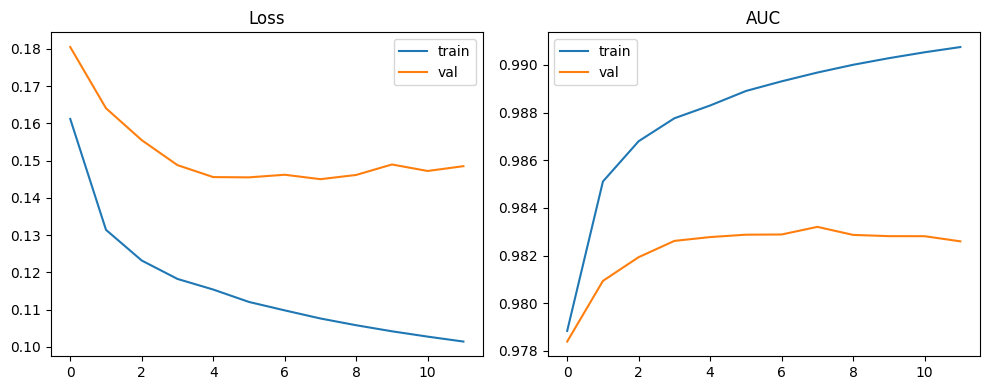

In [ ]:
# Ve lich su train loss vs AUC
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.plot(hist.history["loss"], label="train"); plt.plot(hist.history["val_loss"], label="val")
plt.title("Loss"); plt.legend()
plt.subplot(1, 2, 2); plt.plot(hist.history["auc"], label="train"); plt.plot(hist.history["val_auc"], label="val")
plt.title("AUC"); plt.legend(); plt.tight_layout(); plt.show()


In [ ]:
# Du doan xac suat cua NN tren val/test lam dau vao cho XGBoost
nn_va = model.predict([Xva_c, Xva_hs], batch_size=1024, verbose=0).ravel()
nn_te = model.predict([Xte_c, Xte_hs], batch_size=1024, verbose=0).ravel()
print("NN rieng tren test - AUC:", round(roc_auc_score(yte, nn_te), 4))


NN rieng tren test - AUC: 0.985


In [ ]:
# Train XGBoost tren tap val NN chua thay val luc train suy ra khong ro ri
# Stack: xac suat NN, 41 dac trung da chuan hoa, 128 chieu F2 = 170 cot
Xva_stack = np.column_stack([nn_va, Xva_hs, Xva_f2])
Xte_stack = np.column_stack([nn_te, Xte_hs, Xte_f2])
xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                    n_jobs=-1, random_state=SEED)
xgb.fit(Xva_stack, yva)
print("XGBoost da train xong tren val:", Xva_stack.shape)


XGBoost da train xong tren val: (226603, 170)


In [ ]:
# Tune nguong F1 tren val
probs_va = xgb.predict_proba(Xva_stack)[:, 1]
best_t, best_f1 = 0.5, 0.0
for t in np.arange(0.05, 0.95, 0.01):
    f1 = f1_score(yva, (probs_va >= t).astype(int))
    if f1 > best_f1:
        best_f1, best_t = f1, t
print("Nguong tot nhat tren val:", round(best_t, 2), "| F1 val:", round(best_f1, 4))


Nguong tot nhat tren val: 0.45 | F1 val: 0.9493


In [ ]:
# Danh gia cuoi cung tren tap test ko train
probs_te = xgb.predict_proba(Xte_stack)[:, 1]
pred_te = (probs_te >= best_t).astype(int)
print("=== Hybrid (NN + XGBoost) tren TEST ===")
print("AUC:", round(roc_auc_score(yte, probs_te), 4))
print(classification_report(yte, pred_te, target_names=["legit", "phishing"], digits=4))
print("Confusion matrix [legit/phishing]:\n", confusion_matrix(yte, pred_te))


=== Hybrid (NN + XGBoost) tren TEST ===
AUC: 0.9851
              precision    recall  f1-score   support

       legit     0.9266    0.9769    0.9511    131033
    phishing     0.9771    0.9272    0.9515    139304

    accuracy                         0.9513    270337
   macro avg     0.9519    0.9521    0.9513    270337
weighted avg     0.9526    0.9513    0.9513    270337

Confusion matrix [legit/phishing]:
 [[128007   3026]
 [ 10141 129163]]


In [ ]:
# Danh gia PR-AUC, Recall@FPR=1%, ablation 18 vs 41 vs 41+F2 dac trung
err_idx = np.where(pred_te != yte)[0]
err_df = pd.DataFrame({
    "url": test_df["url"].values[err_idx],
    "y_true": yte[err_idx],
    "label_true": np.where(yte[err_idx] == 1, "phishing", "legit"),
    "prob_phishing": probs_te[err_idx],
    "y_pred": pred_te[err_idx],
    "label_pred": np.where(pred_te[err_idx] == 1, "phishing", "legit"),
})
def _err_type(u):
    # phan loai THO ca sai theo URL ip > homoglyph > brand > khac
    s = str(u).lower()
    host, path, query = safe_parse(s)
    if re.fullmatch(r"\d+\.\d+\.\d+\.\d+", host):
        return "ip"
    if any(ord(c) > 127 for c in s) or "xn--" in host:
        return "homoglyph"
    sk = skeletonize(s)
    h2, p2, _ = safe_parse(sk)
    toks2 = _host_tokens(h2) + _host_tokens(p2)
    if any(_brand_in_tokens(toks2, b) for b in BRANDS):
        return "brand"
    return "khac"
err_df["err_type"] = [_err_type(u) for u in err_df["url"]]
err_df.to_csv("test_errors_08.csv", index=False)
print("Da luu test_errors_08.csv:", len(err_df), "ca sai /", len(yte), "URL test")
print("Bang tom tat ca sai (loai x nhan that):")
print(err_df.groupby(["err_type", "label_true"]).size())
missed = err_df[err_df["label_true"] == "phishing"].nsmallest(5, "prob_phishing")
print("5 ca BO SOT phishing (that phishing, doan legit, prob thap nhat):")
for _, r in missed.iterrows():
    print("  ", r["url"], "| prob:", round(float(r["prob_phishing"]), 4), "| loai:", r["err_type"])
false_al = err_df[err_df["label_true"] == "legit"].nlargest(5, "prob_phishing")
print("5 ca BAO NHAM legit (that legit, doan phishing, prob cao nhat):")
for _, r in false_al.iterrows():
    print("  ", r["url"], "| prob:", round(float(r["prob_phishing"]), 4), "| loai:", r["err_type"])
pr_auc = average_precision_score(yte, probs_te)
fpr, tpr, thr = roc_curve(yte, probs_te)
idx = np.where(fpr <= 0.01)[0]
recall_at_1pct = float(tpr[idx].max()) if len(idx) else 0.0
thr_at_1pct = float(thr[idx[np.argmax(tpr[idx])]]) if len(idx) else float("nan")
print("PR-AUC test:", round(pr_auc, 4))
print("Recall@FPR=1%:", round(recall_at_1pct, 4), "| nguong tuong ung:", round(thr_at_1pct, 4))
# Ablation: XGB stacking tren 18 dac trung cu (F1) vs du 41 (F1+F4) vs 41+F2 (F1+F2+F4)
xgb_old = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                        subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                        n_jobs=-1, random_state=SEED)
xgb_old.fit(np.column_stack([nn_va, Xva_hs[:, :18]]), yva)
probs_old = xgb_old.predict_proba(np.column_stack([nn_te, Xte_hs[:, :18]]))[:, 1]
pred_old = (probs_old >= best_t).astype(int)
xgb_41 = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                       subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                       n_jobs=-1, random_state=SEED)
xgb_41.fit(np.column_stack([nn_va, Xva_hs]), yva)
probs_41 = xgb_41.predict_proba(np.column_stack([nn_te, Xte_hs]))[:, 1]
pred_41 = (probs_41 >= best_t).astype(int)
print("Ablation TEST | XGB 18 dac trung: AUC", round(roc_auc_score(yte, probs_old), 4),
      "| acc", round((pred_old == yte).mean(), 4), "| F1", round(f1_score(yte, pred_old), 4))
print("Ablation TEST | XGB 41 dac trung: AUC", round(roc_auc_score(yte, probs_41), 4),
      "| acc", round((pred_41 == yte).mean(), 4), "| F1", round(f1_score(yte, pred_41), 4))
print("Ablation TEST | XGB 41+F2 dac trung: AUC", round(roc_auc_score(yte, probs_te), 4),
      "| acc", round((pred_te == yte).mean(), 4), "| F1", round(f1_score(yte, pred_te), 4))


Da luu test_errors_08.csv: 13167 ca sai / 270337 URL test
Bang tom tat ca sai (loai x nhan that):
err_type   label_true
brand      legit            74
           phishing         99
homoglyph  legit             4
           phishing          6
khac       legit          2948
           phishing      10036
dtype: int64
5 ca BO SOT phishing (that phishing, doan legit, prob thap nhat):
   https://www.hupaidq.com/news/1771.html | prob: 0.0001 | loai: khac
   https://moh.gov.gm/ | prob: 0.0002 | loai: khac
   https://www.flowcode.com/page/listentobtvoicecall | prob: 0.0004 | loai: khac
   https://www.wizxpert.com/outlook-is-missing-in-quickbooks-desktop/ | prob: 0.0004 | loai: khac
   https://www.spellgod.com/details.php?id=mermaid-spells | prob: 0.0005 | loai: khac
5 ca BAO NHAM legit (that legit, doan phishing, prob cao nhat):
   https://m.mariohut01.top/ | prob: 0.9999 | loai: khac
   https://b1z23y89k290ca0g1c.zzacjt.com/ | prob: 0.9998 | loai: khac
   https://openai.com/&usg=aovvaw0428u

In [ ]:
# Ham du doan 1 URL
TRUSTED = {"google.com", "youtube.com", "wikipedia.org", "amazon.com", "facebook.com",
           "instagram.com", "twitter.com", "linkedin.com", "microsoft.com", "apple.com",
           "netflix.com", "paypal.com", "github.com", "stackoverflow.com",
           "microsoftonline.com", "live.com",
           "vnexpress.net", "thanhnien.vn", "vietnamnet.vn", "tuoitre.vn",
           "dantri.com.vn", "zingnews.vn"}
def predict_url(url):
    u = str(url).strip().lower()
    rd = registrable_domain(u)
    if rd in TRUSTED:  # whitelist dung: so sanh domain dang ky GOC, khong dung substring
        return {"url": url, "label": "legit", "prob_phishing": 0.0, "note": "whitelist"}
    feat = scaler.transform(np.array([extract_features(u)], dtype=np.float32))
    seq = to_seq([u])
    nn_p = float(model.predict([seq, feat], verbose=0).ravel()[0])
    f2 = svd_f2.transform(tfidf_f2.transform([f2_doc(skeletonize(u))])).astype(np.float32)
    stack = np.column_stack([[nn_p], feat, f2])  # [nn_prob, 41 dac trung, 128 chieu F2] = 170 cot
    p = float(xgb.predict_proba(stack)[:, 1][0])
    return {"url": url, "label": "phishing" if p >= best_t else "legit",
            "prob_phishing": round(p, 4), "nn_prob": round(nn_p, 4)}
# test URL
demo = ["https://www.google.com", "https://www.youtube.com/watch?v=abc",
        "https://www.vietcombank.com.vn", "https://www.amazon.com",
        "https://www.roblox.ly/users/2112515059/profile",
        "https://ig-verifica.freemyip.com/accounts/login/",
        "http://185.23.45.67/login.php",
        "https://secure-login-vietcombank.vn-ul.top/"]
for d in demo:
    print(predict_url(d))


{'url': 'https://www.google.com', 'label': 'legit', 'prob_phishing': 0.0, 'note': 'whitelist'}
{'url': 'https://www.youtube.com/watch?v=abc', 'label': 'legit', 'prob_phishing': 0.0, 'note': 'whitelist'}
{'url': 'https://www.vietcombank.com.vn', 'label': 'legit', 'prob_phishing': 0.0179, 'nn_prob': 0.0078}
{'url': 'https://www.amazon.com', 'label': 'legit', 'prob_phishing': 0.0, 'note': 'whitelist'}
{'url': 'https://www.roblox.ly/users/2112515059/profile', 'label': 'phishing', 'prob_phishing': 0.9684, 'nn_prob': 0.9975}
{'url': 'https://ig-verifica.freemyip.com/accounts/login/', 'label': 'phishing', 'prob_phishing': 0.9996, 'nn_prob': 1.0}
{'url': 'http://185.23.45.67/login.php', 'label': 'phishing', 'prob_phishing': 0.9999, 'nn_prob': 1.0}
{'url': 'https://secure-login-vietcombank.vn-ul.top/', 'label': 'phishing', 'prob_phishing': 0.9999, 'nn_prob': 1.0}


In [ ]:
# Tap test homoglyph MO RONG (vong 3, 198 URL): 99 mau cu (mode 0/1/2, dung REV_MAP[0])
# + ~99 mau moi: bien the Cyrillic, Hy Lap, va mixed-script cho moi brand
# Sinh xac dinh loai URL trung voi tap augmentation train
# Bao cao ti le dung cho tung nhom script (orig / cyrillic / greek / mixed)
def _homo_variant(brand, mode):
    # mode 0: thay ky tu dau tien thay duoc; mode 1: thay ky tu thu 2; mode 2: thay 2 ky tu dau
    pos = [i for i, ch in enumerate(brand) if ch in REV_MAP]
    if not pos:
        return None
    b = list(brand)
    if mode == 0:
        b[pos[0]] = REV_MAP[brand[pos[0]]][0]
    elif mode == 1 and len(pos) >= 2:
        b[pos[1]] = REV_MAP[brand[pos[1]]][0]
    elif mode == 2 and len(pos) >= 2:
        b[pos[0]] = REV_MAP[brand[pos[0]]][0]
        b[pos[1]] = REV_MAP[brand[pos[1]]][0]
    else:
        return None
    return "".join(b)

def _script_of_char(c):
    o = ord(c)
    if 0x0400 <= o <= 0x04FF:
        return "cyrillic"
    if 0x0370 <= o <= 0x03FF:
        return "greek"
    return "other"

_homo_rng = random.Random(SEED + 11)
def _homo_variant_script(brand, want):
    # want: "cyrillic" | "greek" | "mixed" — thay 1-2 ky tu bang confusable thuoc script muon
    # "mixed": 1 ky tu Cyrillic + 1 ky tu Hy Lap o 2 vi tri khac nhau
    pos = [i for i, ch in enumerate(brand) if ch in REV_MAP]
    if not pos:
        return None
    b = list(brand)
    if want == "mixed":
        cyr_pos = [p for p in pos if any(_script_of_char(c) == "cyrillic" for c in REV_MAP[brand[p]])]
        grk_pos = [p for p in pos if any(_script_of_char(c) == "greek" for c in REV_MAP[brand[p]])]
        if not cyr_pos or not grk_pos:
            return None
        p1 = cyr_pos[0]
        p2 = next((p for p in grk_pos if p != p1), None)
        if p2 is None:
            return None
        b[p1] = _homo_rng.choice([c for c in REV_MAP[brand[p1]] if _script_of_char(c) == "cyrillic"])
        b[p2] = _homo_rng.choice([c for c in REV_MAP[brand[p2]] if _script_of_char(c) == "greek"])
        return "".join(b)
    chosen = []
    for p in pos:
        opts = [c for c in REV_MAP[brand[p]] if _script_of_char(c) == want]
        if opts:
            chosen.append((p, _homo_rng.choice(opts)))
        if len(chosen) >= 2:
            break
    if not chosen:
        return None
    for p, ch in chosen:
        b[p] = ch
    return "".join(b)

VN_BRANDS = ["vietcombank", "techcombank", "vietinbank", "bidv", "agribank", "sacombank",
             "acb", "mb", "vpbank", "momo", "zalopay", "viettel", "vinaphone", "mobifone",
             "shopee", "lazada", "tiki", "vneid", "dichvucong"]
homo_cases = []  # urlva nhom
for brand in BRANDS:
    tld = ".com.vn" if brand in VN_BRANDS else ".com"
    for mode in (0, 1, 2):
        v = _homo_variant(brand, mode)
        if v:
            homo_cases.append((f"https://www.{v}{tld}/login", "orig"))
    for want in ("cyrillic", "greek", "mixed"):
        v = _homo_variant_script(brand, want)
        if v:
            homo_cases.append((f"https://www.{v}{tld}/login", want))
homo_cases = [(u, g) for (u, g) in homo_cases if u not in AUG_URLS][:200]
print("Tap test homoglyph:", len(homo_cases), "URL")
from collections import Counter as _Counter
print("  theo nhom:", dict(_Counter(g for _, g in homo_cases)))
homo_ok = 0
homo_wrong = []
group_tot = _Counter()
group_ok = _Counter()
for u, g in homo_cases:
    r = predict_url(u)
    group_tot[g] += 1
    if r["label"] == "phishing":
        homo_ok += 1
        group_ok[g] += 1
    else:
        homo_wrong.append((u, g, r["prob_phishing"]))
print("Homoglyph test: dung", homo_ok, "/", len(homo_cases),
      "=", round(homo_ok / max(len(homo_cases), 1), 4), "(muc tieu gan 100%)")
for g in ("orig", "cyrillic", "greek", "mixed"):
    if group_tot[g]:
        print(f"  nhom {g}: dung {group_ok[g]}/{group_tot[g]} = {round(group_ok[g] / group_tot[g], 4)}")
if homo_wrong:
    print("Vi du sai (du doan legit nhung that ra phishing), toi da 3/nhom:")
    _shown = _Counter()
    for u, g, p in homo_wrong:
        if _shown[g] < 3:
            print(" ", f"[{g}]", u, "prob_phishing =", p)
            _shown[g] += 1


Tap test homoglyph: 198 URL
  theo nhom: {'orig': 99, 'cyrillic': 33, 'greek': 33, 'mixed': 33}
Homoglyph test: dung 198 / 198 = 1.0 (muc tieu gan 100%)
  nhom orig: dung 99/99 = 1.0
  nhom cyrillic: dung 33/33 = 1.0
  nhom greek: dung 33/33 = 1.0
  nhom mixed: dung 33/33 = 1.0


In [ ]:
# Luu toan bo pipeline va kiem tra nap lai
model.save("phishing_nn.keras")
xgb.save_model("xgb_model.json")
with open("tokenizer.json", "w") as f:
    f.write(tok.to_json())
with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)
# F2: vectorizer + SVD luu rieng
with open("tfidf_f2.pkl", "wb") as f:
    pickle.dump(tfidf_f2, f)
with open("svd_f2.pkl", "wb") as f:
    pickle.dump(svd_f2, f)
meta = {"model_version": "08", "n_features": 41, "n_features_f2": F2_SVD_DIM,
        "n_features_xgb": 41 + F2_SVD_DIM, "tfidf_max_features": F2_MAX_FEATURES,
        "tfidf_min_df": F2_MIN_DF, "dataset_file": DATA_PATH,
        "threshold": float(best_t), "max_len": MAX_LEN, "label_convention": "file: 0=phishing, 1=legit",
        "feature_names": FEATURE_NAMES, "trusted_domains": sorted(TRUSTED),
        "brands": BRANDS, "sus_kw": SUS_KW, "sus_tld": sorted(SUS_TLD)}
with open("meta.json", "w") as f:
    json.dump(meta, f, indent=1)
print("Da luu: phishing_nn.keras, xgb_model.json, tokenizer.json, scaler.pkl, tfidf_f2.pkl, svd_f2.pkl, meta.json")
# Kiem tra fix nap lai 2 URL 
model2 = load_model("phishing_nn.keras")
with open("tokenizer.json") as f:
    tok2 = tokenizer_from_json(f.read())
with open("scaler.pkl", "rb") as f:
    scaler2 = pickle.load(f)
with open("tfidf_f2.pkl", "rb") as f:
    tfidf_f2b = pickle.load(f)
with open("svd_f2.pkl", "rb") as f:
    svd_f2b = pickle.load(f)
print("Nap lai OK, vocab:", len(tok2.word_index) + 1,
      "| F2 vocab:", len(tfidf_f2b.vocabulary_), "| SVD:", svd_f2b.n_components, "chieu")


Da luu: phishing_nn.keras, xgb_model.json, tokenizer.json, scaler.pkl, tfidf_f2.pkl, svd_f2.pkl, meta.json
Nap lai OK, vocab: 650 | F2 vocab: 10000 | SVD: 128 chieu


In [ ]:
# Tong ket 
print("File train:", DATA_PATH)
print("Tong dong sau lam sach:", len(df), "| train can bang:", len(train_bal),
      "| augmentation homoglyph:", N_AUG, "| augmentation gia mao thuong hieu:", N_AUG_BRAND)
print("So dac trung: 41 (F1+F4, gom 9 homoglyph) + F2 TF-IDF/SVD", F2_SVD_DIM, "chieu =", 41 + F2_SVD_DIM, "cho XGBoost | nguong ap dung:", round(best_t, 2))
print("Ket qua TEST + PR-AUC + Recall@FPR=1% + ablation + homoglyph test (xem cac cell danh gia phia tren)")
print("File ca sai test: test_errors_08.csv (url, nhan that, prob, nhan doan, loai) — dung de phan tich vong sau")
print("Muon dung lai: nap 7 file artifacts o cell tren + goi predict_url(url)")


File train: /kaggle/input/datasets/cuongvnc/dataset-url-v6/dataset_url_06.csv
Tong dong sau lam sach: 2911610 | train can bang: 2293664 | augmentation homoglyph: 40000 | augmentation gia mao thuong hieu: 30000
So dac trung: 41 (F1+F4, gom 9 homoglyph) + F2 TF-IDF/SVD 128 chieu = 169 cho XGBoost | nguong ap dung: 0.45
Ket qua TEST + PR-AUC + Recall@FPR=1% + ablation + homoglyph test (xem cac cell danh gia phia tren)
File ca sai test: test_errors_08.csv (url, nhan that, prob, nhan doan, loai) — dung de phan tich vong sau
Muon dung lai: nap 7 file artifacts o cell tren + goi predict_url(url)


In [ ]:
# Phan tich nguong danh gia tren TEST va benchmark
_thr_list = [0.40, 0.45, 0.48, 0.50]
print("=== Phan tich nguong (TEST + benchmark) — chi bao cao, nguong ap dung van la", round(best_t, 2), "===")
for _t in _thr_list:
    _pred = (probs_te >= _t).astype(int)
    _acc = float((_pred == yte).mean())
    _tp = int(((_pred == 1) & (yte == 1)).sum())
    _fn = int(((_pred == 0) & (yte == 1)).sum())
    _fp = int(((_pred == 1) & (yte == 0)).sum())
    _tn = int(((_pred == 0) & (yte == 0)).sum())
    _rec = _tp / max(_tp + _fn, 1)
    _far = _fp / max(_fp + _tn, 1)
    print(f"  nguong {_t:.2f}: TEST acc {_acc:.4f} | phishing recall {_rec:.4f} | bao nham {_far:.4f} ({_fp}/{_fp + _tn}) | bo sot {_fn}")
_bench_cands2 = sorted(glob.glob("/kaggle/input/datasets/cuongvnc/benchmark/benchmark.csv", recursive=True)) + ["benchmark.csv"]
_bench_path2 = next((p for p in _bench_cands2 if os.path.exists(p)), None)
if _bench_path2:
    _b2 = pd.read_csv(_bench_path2, encoding="utf-8-sig")
    _b2_probs, _b2_wl = [], []
    for _, _row in _b2.iterrows():
        _r = predict_url(_row["url"])
        _b2_probs.append(_r["prob_phishing"])
        _b2_wl.append(_r.get("note") == "whitelist")
    _b2["prob"] = _b2_probs
    _b2["whitelist"] = _b2_wl
    _b2["y_true"] = (_b2["label"] == FILE_LABEL_PHISHING).astype(int) if _b2["label"].dtype == object else (_b2["label"] == 0).astype(int)
    for _t in _thr_list:
        _bp = (_b2["prob"] >= _t).astype(int)
        _ok = int((_bp == _b2["y_true"]).sum())
        _nw = _b2[~_b2["whitelist"]]
        _ok_nw = int(((_nw["prob"] >= _t).astype(int) == _nw["y_true"]).sum())
        print(f"  nguong {_t:.2f}: benchmark dung {_ok}/{len(_b2)} (khong whitelist {_ok_nw}/{len(_nw)})")
else:
    print("  (khong tim thay benchmark.csv — bo qua phan benchmark)")


=== Phan tich nguong (TEST + benchmark) — chi bao cao, nguong ap dung van la 0.45 ===
  nguong 0.40: TEST acc 0.9505 | phishing recall 0.9318 | bao nham 0.0296 (3877/131033) | bo sot 9502
  nguong 0.45: TEST acc 0.9513 | phishing recall 0.9272 | bao nham 0.0231 (3026/131033) | bo sot 10141
  nguong 0.48: TEST acc 0.9516 | phishing recall 0.9252 | bao nham 0.0203 (2665/131033) | bo sot 10425
  nguong 0.50: TEST acc 0.9515 | phishing recall 0.9241 | bao nham 0.0193 (2527/131033) | bo sot 10571
  nguong 0.40: benchmark dung 98/98 (khong whitelist 60/60)
  nguong 0.45: benchmark dung 97/98 (khong whitelist 59/60)
  nguong 0.48: benchmark dung 97/98 (khong whitelist 59/60)
  nguong 0.50: benchmark dung 97/98 (khong whitelist 59/60)


In [ ]:
# Cham benchmark 98 URL khong nam trong tap train
bench_candidates = sorted(glob.glob("/kaggle/input/**/benchmark.csv", recursive=True)) + ["benchmark.csv"]
BENCH_PATH = next((p for p in bench_candidates if os.path.exists(p)), None)
assert BENCH_PATH, "Khong tim thay benchmark.csv, hay gan dataset benchmark vao notebook"
bench = pd.read_csv(BENCH_PATH, encoding="utf-8-sig")
print("Benchmark:", len(bench), "URL | phan bo nhan:", bench["label"].value_counts().to_dict())
bench_probs, bench_pred, bench_wl = [], [], []
for _, row in bench.iterrows():
    r = predict_url(row["url"])
    bench_probs.append(r["prob_phishing"])
    bench_pred.append(1 if r["label"] == "phishing" else 0)
    bench_wl.append(r.get("note") == "whitelist")
bench["y_true"] = (bench["label"] == FILE_LABEL_PHISHING).astype(int) if bench["label"].dtype == object else (bench["label"] == 0).astype(int)  # benchmark.csv dung nhan so 0=phishing, 1=legit (giong file dataset); chuan ve y noi bo (1=phishing)
bench["prob"] = bench_probs
bench["y_pred"] = bench_pred
bench["whitelist"] = bench_wl
acc = (bench["y_pred"] == bench["y_true"]).mean()
print("Benchmark accuracy (co whitelist):", round(acc, 4),
      f"({int((bench['y_pred'] == bench['y_true']).sum())}/{len(bench)})")
nw = bench[~bench["whitelist"]]
print("Benchmark accuracy (khong tinh whitelist):", round((nw["y_pred"] == nw["y_true"]).mean(), 4),
      f"({len(nw)} URL)")
print("Benchmark AUC:", round(roc_auc_score(bench["y_true"], bench["prob"]), 4))


Benchmark: 98 URL | phan bo nhan: {0: 60, 1: 38}
Benchmark accuracy (co whitelist): 0.9898 (97/98)
Benchmark accuracy (khong tinh whitelist): 0.9833 (60 URL)
Benchmark AUC: 1.0


In [ ]:
# Breakdown benchmark theo nguon va liet ke ca false
for src, g in bench.groupby("source"):
    a = (g["y_pred"] == g["y_true"]).mean()
    print(f"  {src}: {int((g['y_pred'] == g['y_true']).sum())}/{len(g)} = {round(a, 4)}")
print("Confusion matrix [legit/phishing]:\n", confusion_matrix(bench["y_true"], bench["y_pred"]))
wrong = bench[bench["y_pred"] != bench["y_true"]]
print("So ca sai:", len(wrong))
for _, row in wrong.iterrows():
    print(" ", row["url"], "| that:", "phishing" if row["y_true"] == 1 else "legit",
          "| doan:", "phishing" if row["y_pred"] == 1 else "legit",
          "| prob:", row["prob"], "| nguon:", row["source"])


  legit_global: 23/23 = 1.0
  legit_vn: 15/15 = 1.0
  phish_synth_global: 24/25 = 0.96
  phish_synth_vn: 35/35 = 1.0
Confusion matrix [legit/phishing]:
 [[38  0]
 [ 1 59]]
So ca sai: 1
  https://youtube-verify-channel.com/ | that: phishing | doan: legit | prob: 0.4345 | nguon: phish_synth_global
